# Appelle des Bibliothèques

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from fastapi import FastAPI
from pydantic import BaseModel
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report


df= pd.read_csv('dataset_transactions_fraude_5000.csv')
df.head(10)

,transaction_id,amount,transaction_hour,merchant_category,customer_age,customer_country,payment_method,is_international,customer_transaction_count,account_age_days,is_fraud
0,TX100000,124800,21,restaurant,31.0,Nigeria,mobile_money,0,6,839,0
1,TX100001,20500,17,supermarket,38.0,Côte d'Ivoire,bank_transfer,0,5,365,0
2,TX100002,10700,9,fashion,67.0,France,card,0,10,922,0
3,TX100003,134700,1,travel,23.0,Sénégal,mobile_money,1,11,1276,0
4,TX100004,111200,3,supermarket,24.0,Côte d'Ivoire,mobile_money,0,16,2206,0
5,TX100005,51600,5,gaming,35.0,Togo,bank_transfer,0,15,1776,0
6,TX100006,31100,9,travel,52.0,Nigeria,wallet,0,8,2033,0
7,TX100007,10400,21,supermarket,64.0,France,bank_transfer,0,11,2089,0
8,TX100008,107100,2,utilities,50.0,Côte d'Ivoire,mobile_money,0,12,2017,0
9,TX100009,147300,13,electronics,46.0,Côte d'Ivoire,mobile_money,0,15,39,0


# Début de l'EDA

- Exploration du dataset avec:
 
   - Shape pour voir la taille du dataset
   - Dtypes pour voir les types de nos variables
   - ET isnull() pour connaitre le nombre de valeurs manquante  

In [2]:
df.shape

(5000, 11)

In [3]:
df.dtypes

transaction_id                    str
amount                          int64
transaction_hour                int64
merchant_category                 str
customer_age                  float64
customer_country                  str
payment_method                    str
is_international                int64
customer_transaction_count      int64
account_age_days                int64
is_fraud                        int64
dtype: object

In [4]:
missing = df.isnull().mean()*100
missing[missing > 0].sort_values(ascending= False)  

merchant_category    1.5
customer_age         1.5
payment_method       1.5
dtype: float64

### Détermination des outliers

ici nous avons utilisé l'IQR(l'écart interquartile) qui est égale a :
               **Q3** - **Q1**
               
Puis nous avons utiliser l'IQR pour calculer les outliers grace a cette formule:
borne inf= **Q1** - 1.5 * IQR
borne sup= **Q3** + 1.5 * IQR

In [5]:
#det des outliers
q1= df[["amount","customer_transaction_count","account_age_days"]].quantile(0.25)
q3=df[["amount","customer_transaction_count","account_age_days"]].quantile(0.75)
iqr= q3 - q1  #determination de l'écart interquartiles
borne_inf= q1 - 1.5 * iqr
borne_sup= q3 + 1.5 * iqr

#enregistrement des outliers
amount_outliers=  df[(df['amount'] < borne_inf['amount']) | (df['amount'] > borne_sup['amount'])]["amount"]

customer_transaction_outliers= df[(df['customer_transaction_count'] < borne_inf['customer_transaction_count'])\
| (df['customer_transaction_count'] > borne_sup['customer_transaction_count'])]["customer_transaction_count"]

account_age_outliers=  df[(df['account_age_days'] < borne_inf['account_age_days']) | (df['account_age_days'] > borne_sup['account_age_days'])]\
["account_age_days"]

# Visualisation des données

### Repartion d'is_fraud 

On peut observé via le graphique que notre variable cible a un gros déséquilibre des classe qui se traduit par une importante présence de la valeur 0 représantant les **Transaction normales** , par contre la valeurs 1 qui représante **les  transaction frauduleuse** est casi inexistante. On a ainsi:

                                                     0 = 97,28% et 1 = 2,72%

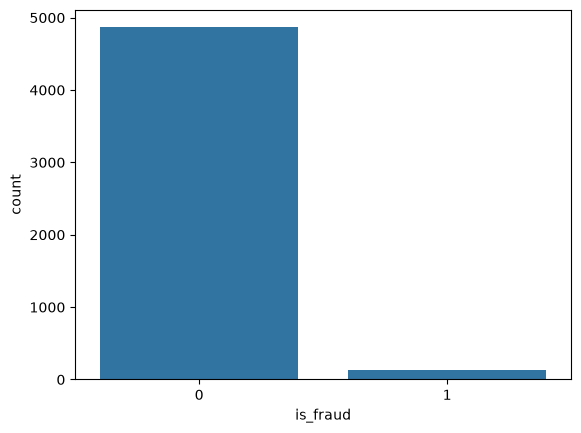

          Nombre  Pourcentage(%)
is_fraud                        
0           4864           97.28
1            136            2.72


In [6]:
sns.countplot(x="is_fraud", data=df)
plt.show()
repartition= df['is_fraud'].value_counts()
proportion= df['is_fraud'].value_counts(normalize= True) * 100
df_repartition= pd.DataFrame({'Nombre': repartition , 'Pourcentage(%)': proportion}) 
print(df_repartition)

### Analyse du Paire_plot

normal = bleus , fraude = orange

1. En regardant la diagonale qui est uniquement constitué de courbe de densité on remarque que les courbe Orange on globalement la même forme que les Bleues, ce qui nous laisse déja présager une difficulté a présire les Fraude.

2. Ensuite viens les Scatter plot du graphique qui confimre la diffuculté de repéré les fraude , car elle sont mélangé/groupé avec les autre

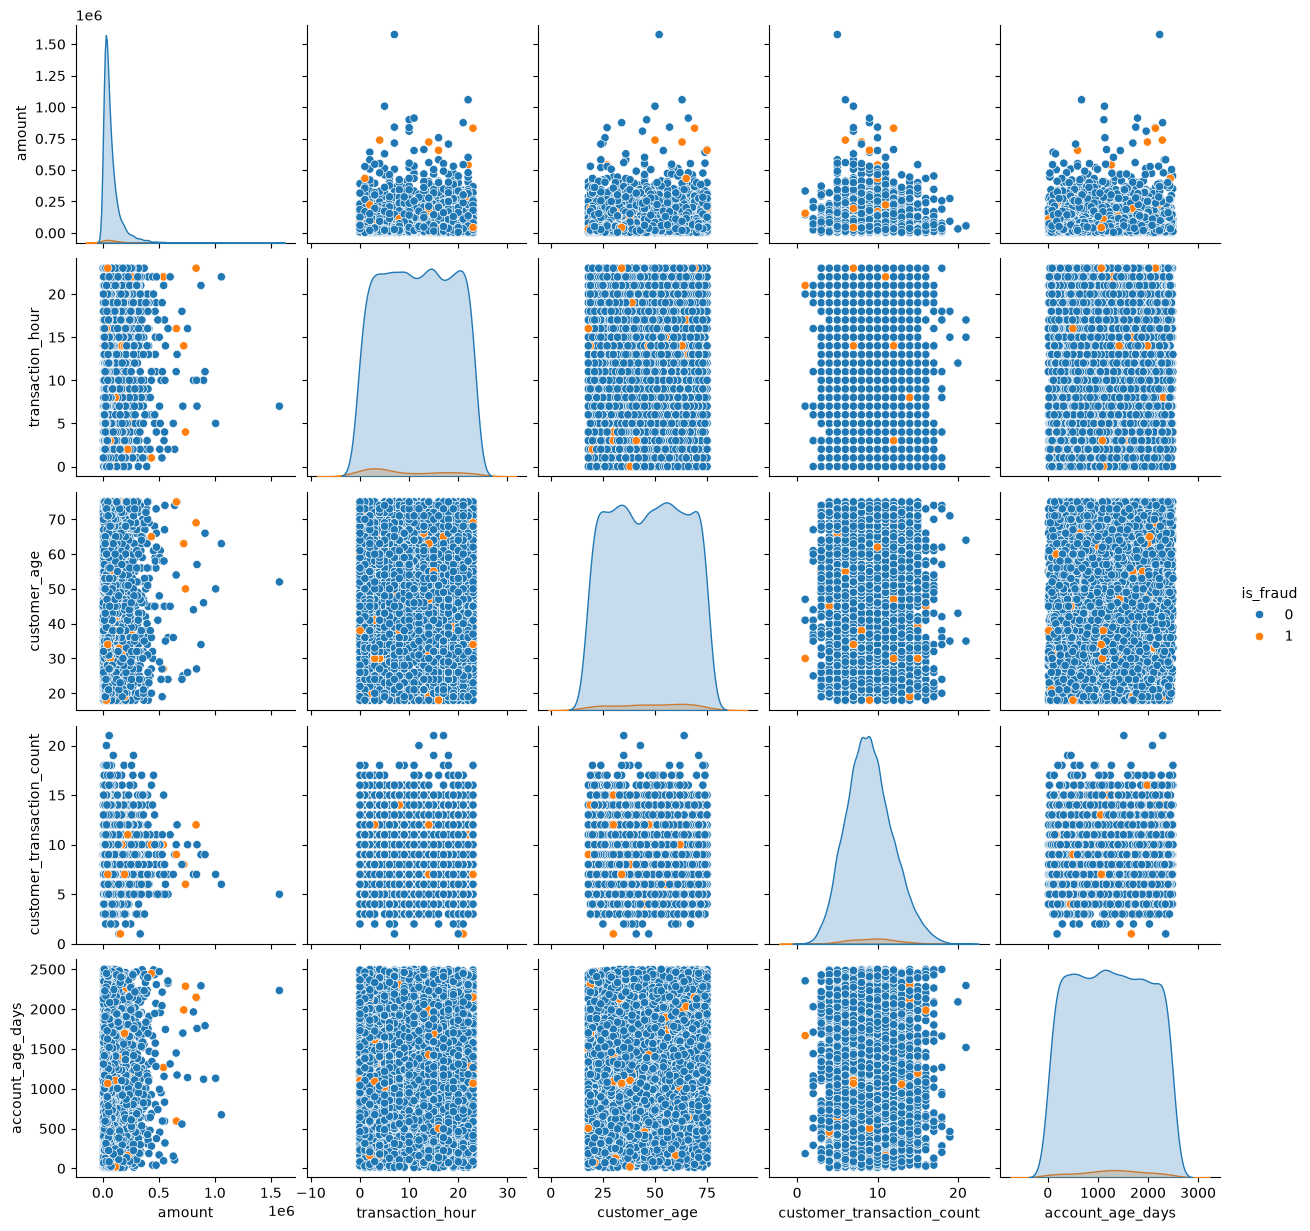

In [7]:
sns.pairplot(df,hue='is_fraud' ,vars=['amount','transaction_hour','customer_age','customer_transaction_count','account_age_days'])
plt.show()

### Analyse de la heat map

la heat map est utilisé pour observé la corrélation entre divérante variable don jeux de donnée.
En regardant le notre on voit que toute les variable on une faible corrélation avec notre variable cible 

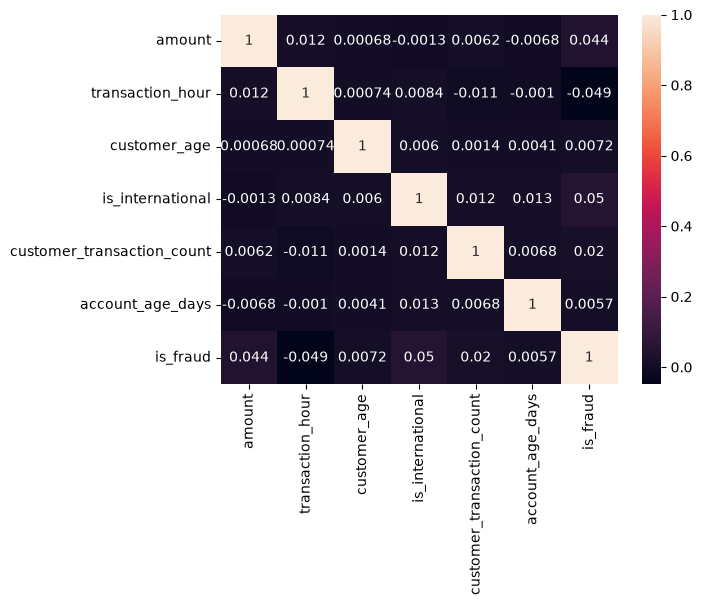

In [8]:
sns.heatmap(df.select_dtypes("number").corr(), annot=True)
plt.show()

# Phase d'entrainement des models

In [32]:
X= df.drop(['is_fraud','transaction_id'], axis=1)
y= df['is_fraud']
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test= train_test_split(X,y, random_state=15, stratify=y, test_size=0.2)  

# Initialisation du préprocesseur pour les colonnes numériques et catégorielles
num= ['amount','customer_age','customer_transaction_count','account_age_days', 'transaction_hour']
cat= ['merchant_category', 'customer_country', 'payment_method']

n_pip = Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])
c_pip = Pipeline(steps= [  
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]
)

trans = ColumnTransformer(transformers= [
    ('numbers', n_pip, num),
    ('categorie', c_pip, cat)
]
)

pip = Pipeline(steps=[   
    ('transformer', trans),
    ('modèle Lr', LogisticRegression(max_iter=1000, random_state=15))
    ]
)

pip.fit(X_train, y_train)
y_pred = pip.predict(X_test)
confusion_matrix(y_test, y_pred)


array([[973,   0],
       [ 27,   0]])

In [ ]:

# param_distributions = {
#     'modèle RF__n_estimators': np.arange(1, 50, 2),
#     'modèle RF__max_depth': [10, 20, None],
#     'modèle RF__min_samples_split': [2, 5, 10]
# }
# model =RandomizedSearchCV(
#     estimator=pip,
#     param_distributions=param_distributions,
#     n_iter=6, # Léger pour votre PC
#     cv=3,
#     scoring='average_precision', 
#     n_jobs=-1,
#     random_state=15
# )

# # L'ajustement est nécessaire avant d'accéder à best_params_
# model.fit(X_train, y_train)

# print(model.best_params_)
# print(model.best_score_)

{'modèle RF__n_estimators': np.int64(3), 'modèle RF__min_samples_split': 5, 'modèle RF__max_depth': None}
0.03678678678678678


In [ ]:
df.head()

,transaction_id,amount,transaction_hour,customer_age,is_international,customer_transaction_count,account_age_days,is_fraud,merchant_category_fashion,merchant_category_gaming,...,merchant_category_utilities,customer_country_Côte d'Ivoire,customer_country_France,customer_country_Ghana,customer_country_Nigeria,customer_country_Sénégal,customer_country_Togo,payment_method_card,payment_method_mobile_money,payment_method_wallet
0,TX100000,124800,21,31.0,0,6,839,0,False,False,...,False,False,False,False,True,False,False,False,True,False
1,TX100001,20500,17,38.0,0,5,365,0,False,False,...,False,True,False,False,False,False,False,False,False,False
2,TX100002,10700,9,67.0,0,10,922,0,True,False,...,False,False,True,False,False,False,False,True,False,False
3,TX100003,134700,1,23.0,1,11,1276,0,False,False,...,False,False,False,False,False,True,False,False,True,False
4,TX100004,111200,3,24.0,0,16,2206,0,False,False,...,False,True,False,False,False,False,False,False,True,False


## Test des modèles sur de nouvlle donnée

La fonction si dessous (**predire_transaction**) permettra d'évalué mes models sur de nouvelle donné.

  

In [ ]:
def predire_transaction(
    transaction_dict,
    modele,
    colonnes_attendues,
    scaler=None,
    seuil=0.05
):
    # 1. Dictionnaire → DataFrame
    df_transaction = pd.DataFrame([transaction_dict])

    # 2. Ajouter les colonnes manquantes
    for col in colonnes_attendues:
        if col not in df_transaction.columns:
            df_transaction[col] = 0

    # 3. Même ordre que pendant l'entraînement
    df_transaction = df_transaction[colonnes_attendues]

    # 4. Scaling si nécessaire
    if scaler is not None:
        df_transaction = scaler.transform(df_transaction)

    # 5. Probabilité de fraude
    proba_fraude = modele.predict_proba(df_transaction)[0, 1]


    print(f"Résultat : {prediction}")
    print(f"Probabilité de fraude : {proba_fraude * 100:.1f} %")

    return prediction, proba_fraude


# Utilisation
transaction = {
    "amount": 750000,
    "transaction_hour": 2,
    "customer_age": 23,
    "is_international": 1,
    "customer_transaction_count": 1,
    "account_age_days": 20
}

predire_transaction(transaction, m_rf, X_train.columns.tolist())

Résultat : FRAUDE PROBABLE
Probabilité de fraude : 43.7 %


('FRAUDE PROBABLE', np.float64(0.43707914030957257))

# Analyse avec SHAP
l'utilisation de SHAP a parmie de savoir quelle variable pesait le plus dans les prédiction de chaque model, ainsi nous pouvons comprendre les résultat précédent 

- Le random forest ce base en grande partie sur l'heure des transaction pour identifié les transaction frauduleuse.
- La regression logistique quant a elle ce concentre beacoup sur sur le pays du client masi attention contrairement au random forest d'autre variable comme *la méthode de payment* et l'heure de la transaction son non négligabe et on également un poids concéquant dans 

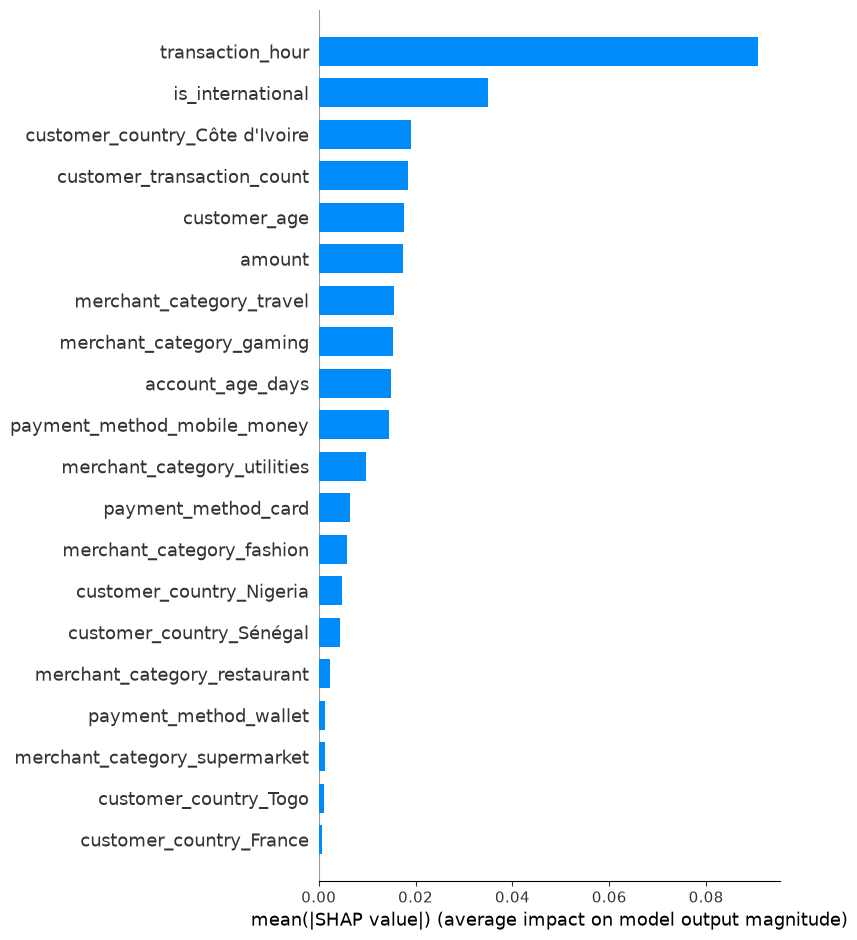

In [ ]:
import shap

explainer = shap.Explainer(model)          # TreeExplainer = plus adapté et plus rapide pour une Random Forest
X_sample = X_test.sample(n=300, random_state=15)  # échantillon pour aller plus vite (optionnel, tu peux mettre X_test entier)
shap_values = explainer.shap_values(X_sample)

# Ne garder que la classe "fraude" (indice 1)
sv_fraude = shap_values[:, :, 1] if not isinstance(shap_values, list) else shap_values[1]

shap.summary_plot(sv_fraude, X_sample, plot_type="bar")

Background dataset has 4000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=4000 when initializing the masker.


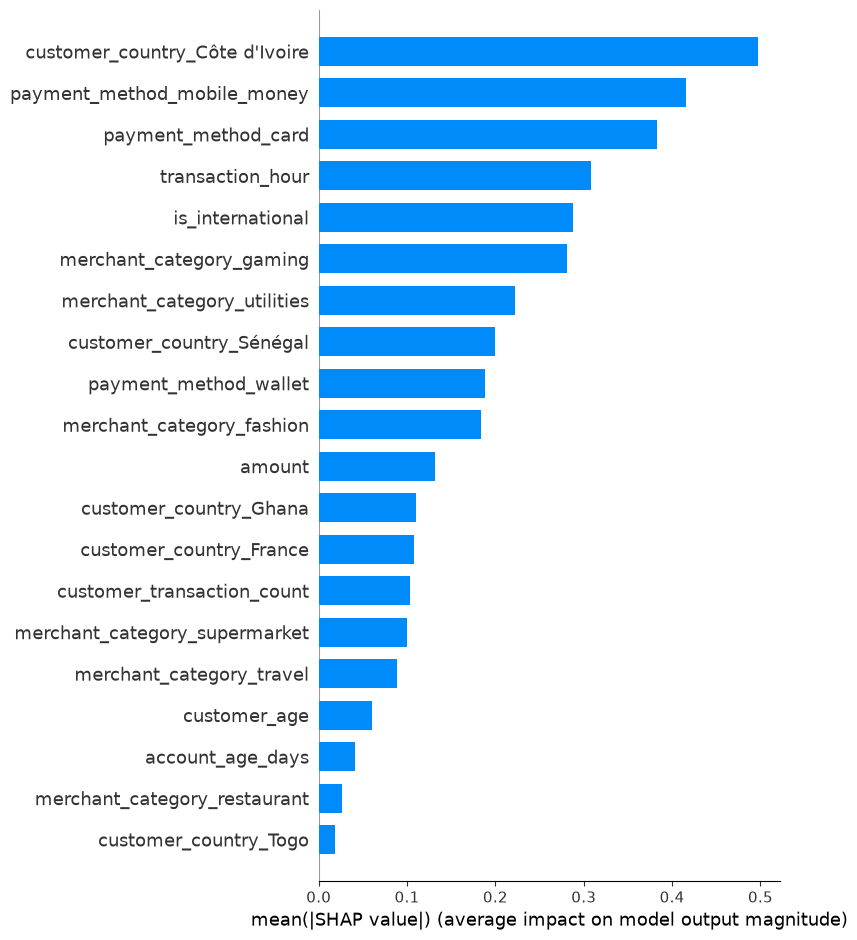

In [ ]:
import shap

explainer = shap.LinearExplainer(model)   # LinearExplainer, pas TreeExplainer, pour un modèle linéaire

X_sample = X_test.sample(n=300, random_state=15)
X_sample_scaled = scaler.transform(X_sample)   # important : m_logistic a été entraîné sur des données standardisées

shap_values = explainer.shap_values(X_sample_scaled)

shap.summary_plot(shap_values, X_sample_scaled, feature_names=X_test.columns, plot_type="bar")